# Telecom Customer Churn: BI and Predictive Analytics

Analyze customer churn, compare predictive models, and translate risk scores into retention-planning KPIs and an editable business-case scenario.

- **Target:** `Churn` (`1` = churned, `0` = retained)
- **Dataset:** 3,333 records, 10 input features, and one target column
- **BI focus:** churn KPIs, segment comparisons, campaign capacity, and scenario-based economics
- **Predictive approach:** cross-validated model comparison, held-out evaluation, and risk prioritization

> The dataset has no customer ID, timestamp, actual campaign outcomes, or customer-margin data. Business-case values are illustrative inputs, not observed financial results.

# 1. Import Libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve, precision_recall_curve
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 2. Load the data

In [2]:
candidate_paths = [
    Path("/kaggle/input/datasets/barun2104/telecom-churn/telecom_churn.csv"),
    Path("telecom_churn.csv"),
]

DATA_PATH = next(
    (path for path in candidate_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Check the Kaggle input path."
    )

df = pd.read_csv(DATA_PATH)

print(f"Loaded: {DATA_PATH}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

display(df.head())


Loaded: /kaggle/input/datasets/barun2104/telecom-churn/telecom_churn.csv
Rows: 3,333 | Columns: 11


,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


## 3. Data quality

In [3]:
quality = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique(),
})
display(quality)

print(f"Duplicate rows: {df.duplicated().sum():,}")
print("\nTarget counts:")
display(df["Churn"].value_counts().sort_index().rename(index={0: "Retained (0)", 1: "Churned (1)"}))

expected_target_values = {0, 1}
if set(df["Churn"].dropna().unique()) != expected_target_values:
    raise ValueError("Expected Churn to contain only 0 and 1.")

,Data type,Missing values,Unique values
Churn,int64,0,2
AccountWeeks,int64,0,212
ContractRenewal,int64,0,2
DataPlan,int64,0,2
DataUsage,float64,0,174
CustServCalls,int64,0,10
DayMins,float64,0,1667
DayCalls,int64,0,119
MonthlyCharge,float64,0,627
OverageFee,float64,0,1024


Duplicate rows: 0

Target counts:


Churn
Retained (0)    2850
Churned (1)      483
Name: count, dtype: int64

## 4. Exploratory data analysis

### Target distribution

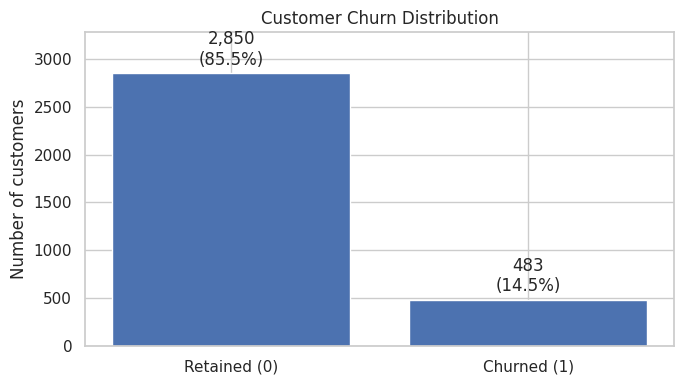

Overall churn rate: 14.5%


In [4]:
target_counts = df["Churn"].value_counts().sort_index()
target_labels = ["Retained (0)", "Churned (1)"]
target_percent = target_counts / target_counts.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(target_labels, target_counts.values)
ax.set_title("Customer Churn Distribution")
ax.set_ylabel("Number of customers")
ax.bar_label(bars, labels=[f"{n:,}\n({p:.1f}%)" for n, p in zip(target_counts.values, target_percent.values)], padding=3)
ax.set_ylim(0, max(target_counts.values) * 1.15)
plt.tight_layout()
plt.show()

print(f"Overall churn rate: {df['Churn'].mean():.1%}")

### Churn rates by contract renewal and data plan

These rates show associations in this dataset; they do not prove causation.

,Feature,Value,Customers,Churn_Rate
0,ContractRenewal,0,323,42.4%
1,ContractRenewal,1,3010,11.5%
2,DataPlan,0,2411,16.7%
3,DataPlan,1,922,8.7%


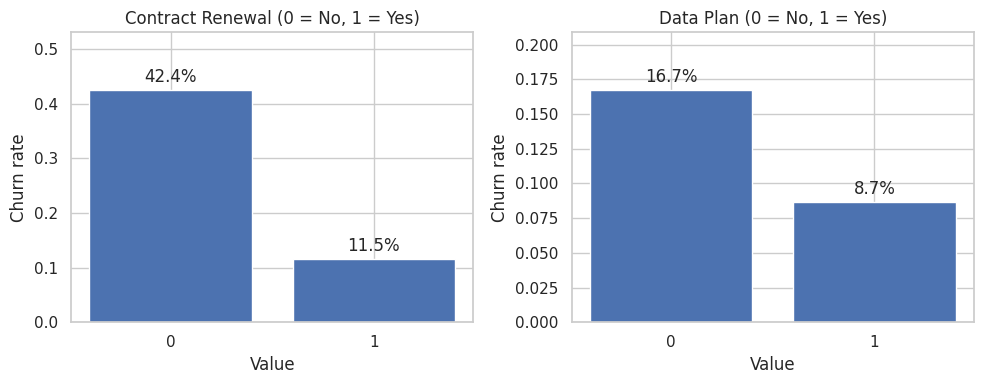

In [5]:
rate_rows = []
for feature in ["ContractRenewal", "DataPlan"]:
    temp = df.groupby(feature)["Churn"].agg(Customers="size", Churn_Rate="mean").reset_index()
    temp["Feature"] = feature
    rate_rows.append(temp.rename(columns={feature: "Value"}))

rate_table = pd.concat(rate_rows, ignore_index=True)[["Feature", "Value", "Customers", "Churn_Rate"]]
display(rate_table.style.format({"Churn_Rate": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
feature_titles = {
    "ContractRenewal": ("Contract Renewal (0 = No, 1 = Yes)", axes[0]),
    "DataPlan": ("Data Plan (0 = No, 1 = Yes)", axes[1]),
}
for feature, (title, ax) in feature_titles.items():
    rates = df.groupby(feature)["Churn"].mean()
    bars = ax.bar(rates.index.astype(str), rates.values)
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Churn rate")
    ax.set_ylim(0, max(rates.values) * 1.25)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in rates.values], padding=3)
plt.tight_layout()
plt.show()

### Numeric feature distributions

Compare churned and retained customers across selected variables. Differences are descriptive, not causal.

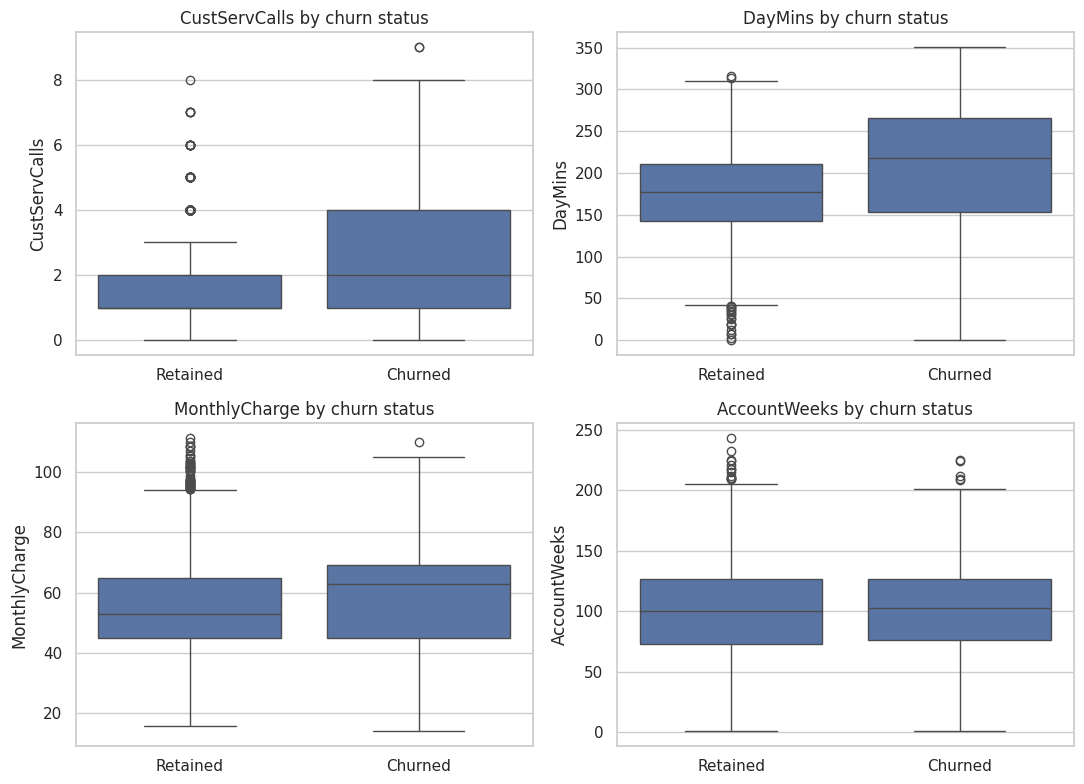

In [6]:
numeric_features = ["CustServCalls", "DayMins", "MonthlyCharge", "AccountWeeks"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for feature, ax in zip(numeric_features, axes.flat):
    plot_data = df[["Churn", feature]].copy()
    plot_data["Churn status"] = plot_data["Churn"].map({0: "Retained", 1: "Churned"})
    sns.boxplot(data=plot_data, x="Churn status", y=feature, order=["Retained", "Churned"], ax=ax)
    ax.set_title(f"{feature} by churn status")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Initial observations**
- Customers without contract renewal show a higher churn rate in this dataset.
- Customers with a data plan show a lower churn rate in this dataset.
- Service calls and daytime minutes are useful variables to investigate in the predictive model.

These patterns should be validated with business context before using them to set retention policy.

## 5. Prepare training and test sets

The test set is held out for final evaluation. Scaling is placed inside a pipeline to avoid fitting the scaler on test data.

In [7]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Compare different model families.
# The scaler is needed only for Logistic Regression.
model_candidates = {
    "Balanced Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE,
        )),
    ]),
    "Balanced Random Forest": RandomForestClassifier(
        n_estimators=250,
        class_weight="balanced_subsample",
        min_samples_leaf=3,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "HistGradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=RANDOM_STATE,
    ),
}

baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")
print(f"Churn rate — train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")
print("Candidate models:", ", ".join(model_candidates.keys()))

Training rows: 2,499 | Test rows: 834
Churn rate — train: 14.5% | test: 14.5%
Candidate models: Balanced Logistic Regression, Balanced Random Forest, HistGradient Boosting


## 6. Model comparison with cross-validation

Compare three model families on the training split using the same stratified five-fold splits. Select the candidate with the highest mean average precision (useful when the churn class is the minority class). The test set is reserved for final reporting.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

cv_rows = []
cv_results_by_model = {}
for model_name, estimator in model_candidates.items():
    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise",
    )
    cv_results_by_model[model_name] = scores
    cv_rows.append({
        "Model": model_name,
        "CV ROC-AUC (mean)": scores["test_roc_auc"].mean(),
        "CV Average Precision (mean)": scores["test_average_precision"].mean(),
        "CV Precision (mean)": scores["test_precision"].mean(),
        "CV Recall (mean)": scores["test_recall"].mean(),
        "CV F1 (mean)": scores["test_f1"].mean(),
        "AP standard deviation": scores["test_average_precision"].std(),
    })

cv_summary = pd.DataFrame(cv_rows).sort_values(
    "CV Average Precision (mean)", ascending=False
).reset_index(drop=True)
display(cv_summary.style.format({
    "CV ROC-AUC (mean)": "{:.3f}",
    "CV Average Precision (mean)": "{:.3f}",
    "CV Precision (mean)": "{:.3f}",
    "CV Recall (mean)": "{:.3f}",
    "CV F1 (mean)": "{:.3f}",
    "AP standard deviation": "{:.3f}",
}))

best_model_name = cv_summary.loc[0, "Model"]
print(f"Selected model based on training CV average precision: {best_model_name}")
print("This selection is based on cross-validation, not the held-out test results.")

,Model,CV ROC-AUC (mean),CV Average Precision (mean),CV Precision (mean),CV Recall (mean),CV F1 (mean),AP standard deviation
0,Balanced Random Forest,0.917,0.798,0.783,0.721,0.749,0.051
1,HistGradient Boosting,0.901,0.790,0.852,0.669,0.748,0.060
2,Balanced Logistic Regression,0.820,0.446,0.360,0.760,0.488,0.021


Selected model based on training CV average precision: Balanced Random Forest
This selection is based on cross-validation, not the held-out test results.


## 7. Held-out test-set performance

Fit the candidate models on the full training split and report performance once on the held-out test split. Model selection was made using training-only cross-validation. Accuracy is included for context but should not be used alone because churn is the minority class.

In [9]:
# Fit candidates on the training split. Preserve Logistic Regression for coefficient interpretation below.
fitted_models = {}
for model_name, estimator in model_candidates.items():
    estimator.fit(X_train, y_train)
    fitted_models[model_name] = estimator

log_model = fitted_models["Balanced Logistic Regression"]
best_model = fitted_models[best_model_name]

# Include a simple baseline to show how the model compares with predicting the majority class.
def evaluate_model(name, estimator, X_eval, y_eval):
    pred = estimator.predict(X_eval)
    prob = estimator.predict_proba(X_eval)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, prob),
        "Average precision": average_precision_score(y_eval, prob),
    }

comparison_rows = [evaluate_model("Most-frequent baseline", baseline_model, X_test, y_test)]
comparison_rows.extend(
    evaluate_model(name, estimator, X_test, y_test)
    for name, estimator in fitted_models.items()
)
test_comparison = pd.DataFrame(comparison_rows).set_index("Model")
display(test_comparison.style.format("{:.3f}"))

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]
print(f"\nSelected model: {best_model_name}")
print("Classification report at the model's default 0.50 threshold:")
print(classification_report(
    y_test, y_pred,
    target_names=["Retained", "Churned"],
    digits=3,
    zero_division=0,
))

,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision
Model,,,,,,
Most-frequent baseline,0.855,0.000,0.000,0.000,0.500,0.145
Balanced Logistic Regression,0.757,0.341,0.727,0.464,0.814,0.426
Balanced Random Forest,0.908,0.672,0.711,0.691,0.866,0.739
HistGradient Boosting,0.922,0.775,0.653,0.709,0.858,0.751



Selected model: Balanced Random Forest
Classification report at the model's default 0.50 threshold:
              precision    recall  f1-score   support

    Retained      0.950     0.941     0.946       713
     Churned      0.672     0.711     0.691       121

    accuracy                          0.908       834
   macro avg      0.811     0.826     0.818       834
weighted avg      0.910     0.908     0.909       834



### Confusion matrix for the cross-validation-selected model

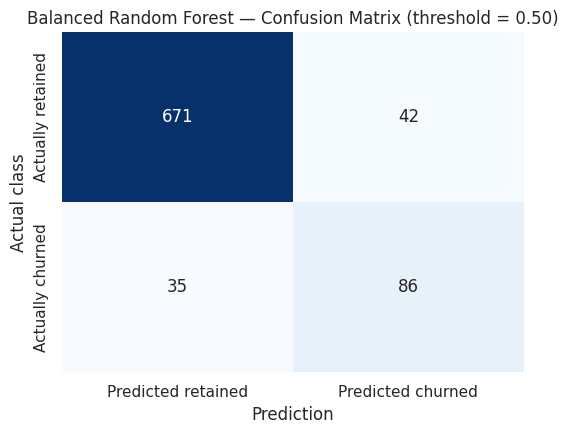

True positives (churners found): 86
False negatives (churners missed): 35
False positives (retained customers flagged): 42
True negatives (retained customers identified): 671


In [10]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Predicted retained", "Predicted churned"],
    yticklabels=["Actually retained", "Actually churned"],
    ax=ax,
)
ax.set_title(f"{best_model_name} — Confusion Matrix (threshold = 0.50)")
ax.set_xlabel("Prediction")
ax.set_ylabel("Actual class")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True positives (churners found): {tp:,}")
print(f"False negatives (churners missed): {fn:,}")
print(f"False positives (retained customers flagged): {fp:,}")
print(f"True negatives (retained customers identified): {tn:,}")

### ROC and precision-recall curves

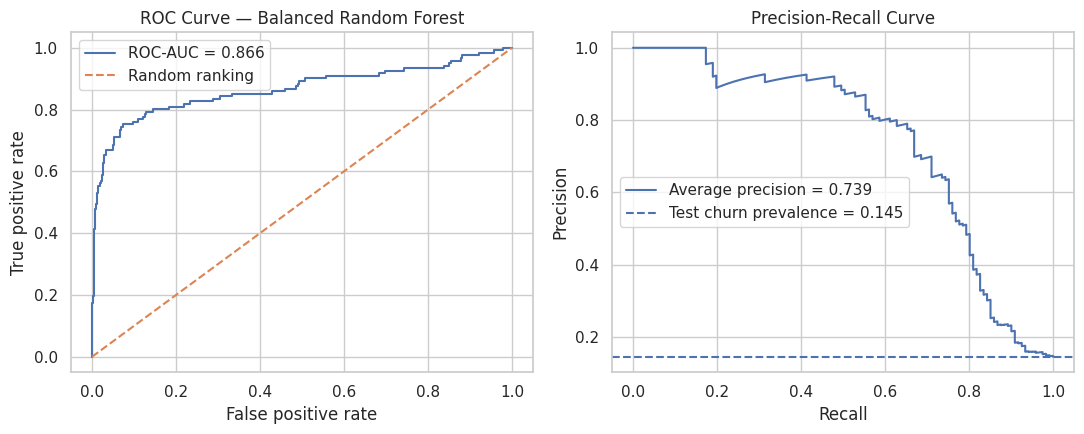

In [11]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_prob)
prevalence = y_test.mean()
roc_auc = roc_auc_score(y_test, y_prob)
avg_precision = average_precision_score(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
axes[0].set(title=f"ROC Curve — {best_model_name}", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend()

axes[1].plot(recall_vals, precision_vals, label=f"Average precision = {avg_precision:.3f}")
axes[1].axhline(prevalence, linestyle="--", label=f"Test churn prevalence = {prevalence:.3f}")
axes[1].set(title="Precision-Recall Curve", xlabel="Recall", ylabel="Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Threshold sensitivity

Changing a classification threshold changes the number of customers flagged, precision, and recall. This table is a sensitivity analysis on the test split, not a rule for choosing the final operating threshold. In practice, agree a contact capacity and campaign economics with the business team, then validate the policy on a fresh time-based sample.

In [12]:
threshold_rows = []
for threshold in [0.25, 0.35, 0.50, 0.65, 0.75]:
    pred_at_threshold = (y_prob >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred_at_threshold, labels=[0, 1]).ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, pred_at_threshold, zero_division=0),
        "Recall": recall_score(y_test, pred_at_threshold, zero_division=0),
        "F1": f1_score(y_test, pred_at_threshold, zero_division=0),
        "Customers flagged": int(pred_at_threshold.sum()),
        "False positives": int(fp_t),
        "False negatives": int(fn_t),
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.style.format({
    "Threshold": "{:.2f}", "Precision": "{:.3f}",
    "Recall": "{:.3f}", "F1": "{:.3f}",
}))

,Threshold,Precision,Recall,F1,Customers flagged,False positives,False negatives
0,0.25,0.482,0.793,0.600,199,103,25
1,0.35,0.572,0.752,0.650,159,68,30
2,0.50,0.672,0.711,0.691,128,42,35
3,0.65,0.804,0.612,0.695,92,18,47
4,0.75,0.894,0.488,0.631,66,7,62


## 9. Logistic Regression coefficient interpretation

This section interprets the Logistic Regression reference model, even if a different model ranks first in cross-validation. Coefficients use standardized inputs. A positive coefficient is associated with higher predicted churn odds and a negative coefficient with lower predicted churn odds, holding other features constant. These are model associations, not causal effects.

,Feature,Standardized coefficient
4,CustServCalls,0.794
5,DayMins,0.488
7,MonthlyCharge,0.279
8,OverageFee,0.262
9,RoamMins,0.171
0,AccountWeeks,0.065
6,DayCalls,0.055
3,DataUsage,-0.087
2,DataPlan,-0.518
1,ContractRenewal,-0.699


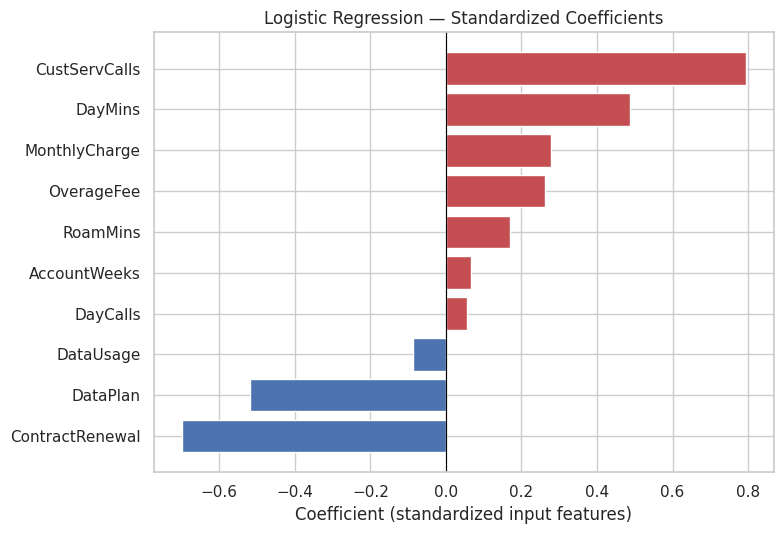

In [13]:
classifier = log_model.named_steps["classifier"]
coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Standardized coefficient": classifier.coef_[0],
}).sort_values("Standardized coefficient")

display(coef_table.sort_values("Standardized coefficient", ascending=False).style.format({
    "Standardized coefficient": "{:.3f}"
}))

fig, ax = plt.subplots(figsize=(8, 5.5))
bar_colors = ["#C44E52" if value > 0 else "#4C72B0" for value in coef_table["Standardized coefficient"]]
ax.barh(coef_table["Feature"], coef_table["Standardized coefficient"], color=bar_colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic Regression — Standardized Coefficients")
ax.set_xlabel("Coefficient (standardized input features)")
plt.tight_layout()
plt.show()

## 10. Optional SHAP explanation for Logistic Regression

This optional section explains the Logistic Regression reference model. SHAP is not used to select the model or establish causal drivers. Install `shap` only if you want to run this section.

Background dataset has 2499 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2499 when initializing the masker.


Global feature importance — Logistic Regression reference model


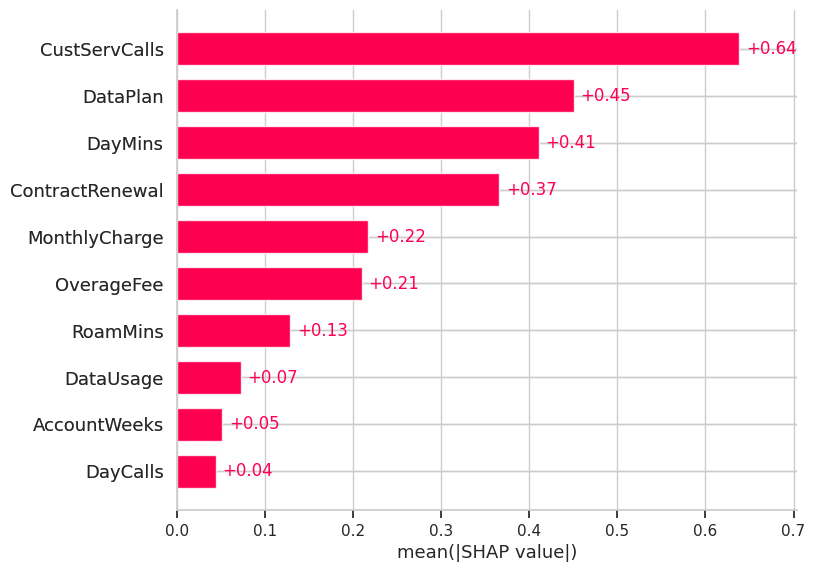

Explanation for the first test-set record


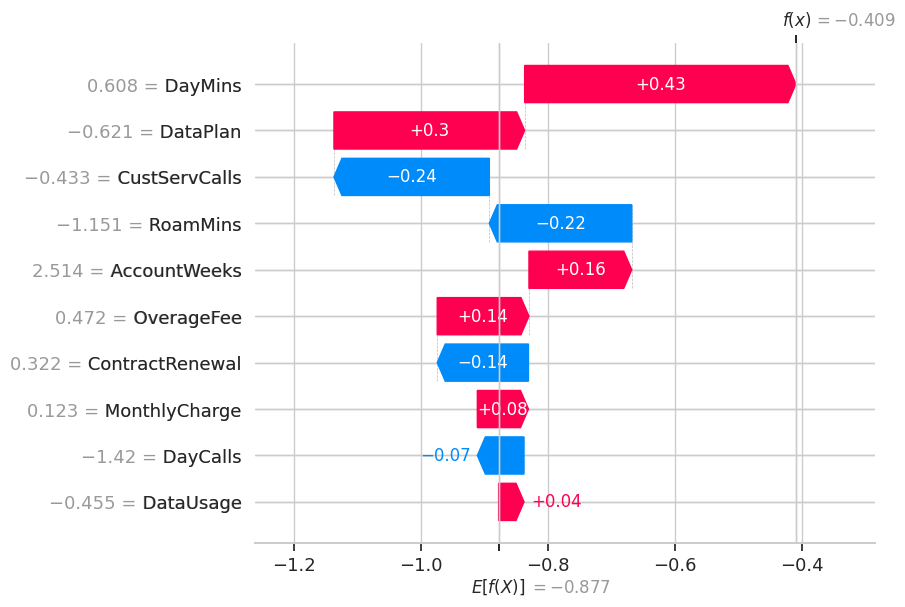

In [14]:
try:
    import shap
    scaled_train = log_model.named_steps["scaler"].transform(X_train)
    scaled_test = log_model.named_steps["scaler"].transform(X_test)
    explainer = shap.LinearExplainer(
        log_model.named_steps["classifier"],
        scaled_train,
        feature_names=list(X.columns),
    )
    shap_values = explainer(scaled_test)

    print("Global feature importance — Logistic Regression reference model")
    shap.plots.bar(shap_values, max_display=10)

    print("Explanation for the first test-set record")
    shap.plots.waterfall(shap_values[0], max_display=10)
except ImportError:
    print("SHAP is not installed. Install it with `%pip install shap` only if you want to run this optional section.")
except Exception as exc:
    print(f"The optional SHAP section could not run in this environment: {type(exc).__name__}: {exc}")

## 11. BI-focused segment KPIs

Segment rates help a BI analyst identify where churn is concentrated. They are descriptive associations, not proof that a segment attribute causes churn. The same KPI table can be exported to a Power BI model or used as the basis for a report page.

In [15]:
# Create business-friendly segment labels and calculate a concise KPI table.
segment_df = df.copy()
segment_df["Contract renewal"] = segment_df["ContractRenewal"].map({0: "No renewal", 1: "Renewal"})
segment_df["Data plan"] = segment_df["DataPlan"].map({0: "No data plan", 1: "Data plan"})
segment_df["Customer service calls band"] = pd.cut(
    segment_df["CustServCalls"],
    bins=[-1, 1, 3, np.inf],
    labels=["0–1 calls", "2–3 calls", "4+ calls"],
)

segment_specs = [
    ("Contract renewal", "Contract renewal status"),
    ("Data plan", "Data plan status"),
    ("Customer service calls band", "Customer service calls"),
]
segment_tables = []
for column, label in segment_specs:
    grouped = segment_df.groupby(column, observed=False)["Churn"].agg(
        Customers="size", Churners="sum", Churn_Rate="mean"
    ).reset_index().rename(columns={column: "Segment"})
    grouped["Segment dimension"] = label
    grouped["Share of all churners"] = grouped["Churners"] / segment_df["Churn"].sum()
    segment_tables.append(grouped[[
        "Segment dimension", "Segment", "Customers", "Churners", "Churn_Rate", "Share of all churners"
    ]])

segment_kpis = pd.concat(segment_tables, ignore_index=True)
display(segment_kpis.style.format({
    "Churn_Rate": "{:.1%}",
    "Share of all churners": "{:.1%}",
}))

print(f"Overall churn rate: {df['Churn'].mean():.1%}")
print("Use customer counts and churn rate together: a high rate in a very small group may represent fewer customers than a moderate rate in a large group.")

,Segment dimension,Segment,Customers,Churners,Churn_Rate,Share of all churners
0,Contract renewal status,No renewal,323,137,42.4%,28.4%
1,Contract renewal status,Renewal,3010,346,11.5%,71.6%
2,Data plan status,Data plan,922,80,8.7%,16.6%
3,Data plan status,No data plan,2411,403,16.7%,83.4%
4,Customer service calls,0–1 calls,1878,214,11.4%,44.3%
5,Customer service calls,2–3 calls,1188,131,11.0%,27.1%
6,Customer service calls,4+ calls,267,138,51.7%,28.6%


Overall churn rate: 14.5%
Use customer counts and churn rate together: a high rate in a very small group may represent fewer customers than a moderate rate in a large group.


## 12. Retention prioritization and business-case scenario

The model can help prioritize outreach by ranking customers by predicted churn risk. Because this dataset contains no customer ID, the sample below is a **retrospective test-set simulation**, not a deployable contact list. Contact capacity and financial values are editable assumptions; they are not provided by the dataset.

In [16]:
# Operational policy: contact the highest-risk 10% of the held-out sample.
# Change this rate to match a real team's outreach capacity.
OUTREACH_CAPACITY_RATE = 0.10

n_to_contact = max(1, int(np.ceil(len(X_test) * OUTREACH_CAPACITY_RATE)))
risk_order = np.argsort(y_prob)[::-1]
target_positions = risk_order[:n_to_contact]
target_y = y_test.iloc[target_positions].to_numpy()

overall_test_churn_rate = float(y_test.mean())
target_churn_rate = float(target_y.mean())
total_test_churners = int(y_test.sum())
churners_captured = int(target_y.sum())

prioritization_summary = pd.DataFrame([{
    "Test-set customers": len(X_test),
    "Outreach capacity": OUTREACH_CAPACITY_RATE,
    "Customers prioritized": n_to_contact,
    "Share of test-set churners captured": churners_captured / total_test_churners if total_test_churners else np.nan,
    "Churn rate among prioritized customers": target_churn_rate,
    "Overall test-set churn rate": overall_test_churn_rate,
    "Churn-rate lift vs. test average": target_churn_rate / overall_test_churn_rate if overall_test_churn_rate else np.nan,
}])
display(prioritization_summary.style.format({
    "Outreach capacity": "{:.1%}",
    "Share of test-set churners captured": "{:.1%}",
    "Churn rate among prioritized customers": "{:.1%}",
    "Overall test-set churn rate": "{:.1%}",
    "Churn-rate lift vs. test average": "{:.2f}x",
}))

print("Interpretation: these are retrospective test-set results. Churn concentration among prioritized customers does not prove a retention campaign would prevent those churns.")

,Test-set customers,Outreach capacity,Customers prioritized,Share of test-set churners captured,Churn rate among prioritized customers,Overall test-set churn rate,Churn-rate lift vs. test average
0,834,10.0%,84,56.2%,81.0%,14.5%,5.58x


Interpretation: these are retrospective test-set results. Churn concentration among prioritized customers does not prove a retention campaign would prevent those churns.


### Editable financial assumptions

The CSV has no campaign cost or customer-margin data. Replace the illustrative values below with figures supplied by Finance/Marketing before using the scenario for a real decision. “Incremental retention rate” means the assumed percentage of contacted customers retained **because of** the campaign, not the model's predicted churn probability.

In [17]:
# ILLUSTRATIVE INPUTS ONLY — replace with business-approved values.
CONTACT_COST_PER_CUSTOMER = 10.0
CONTRIBUTION_MARGIN_PER_RETAINED_CUSTOMER = 300.0
INCREMENTAL_RETENTION_RATE = 0.05

contacted_customers = n_to_contact
expected_incremental_saves = contacted_customers * INCREMENTAL_RETENTION_RATE
campaign_cost = contacted_customers * CONTACT_COST_PER_CUSTOMER
expected_incremental_value = expected_incremental_saves * CONTRIBUTION_MARGIN_PER_RETAINED_CUSTOMER
expected_net_value = expected_incremental_value - campaign_cost
roi = expected_net_value / campaign_cost if campaign_cost > 0 else np.nan
breakeven_retention_rate = (
    CONTACT_COST_PER_CUSTOMER / CONTRIBUTION_MARGIN_PER_RETAINED_CUSTOMER
    if CONTRIBUTION_MARGIN_PER_RETAINED_CUSTOMER > 0 else np.nan
)

business_case = pd.DataFrame([{
    "Customers contacted (test simulation)": contacted_customers,
    "Contact cost per customer (assumption)": CONTACT_COST_PER_CUSTOMER,
    "Incremental retention rate (assumption)": INCREMENTAL_RETENTION_RATE,
    "Contribution margin per retained customer (assumption)": CONTRIBUTION_MARGIN_PER_RETAINED_CUSTOMER,
    "Expected incremental saves (scenario)": expected_incremental_saves,
    "Estimated campaign cost": campaign_cost,
    "Estimated incremental value": expected_incremental_value,
    "Estimated net value": expected_net_value,
    "Estimated ROI": roi,
    "Break-even incremental retention rate": breakeven_retention_rate,
}])
display(business_case.style.format({
    "Contact cost per customer (assumption)": "{:,.2f}",
    "Incremental retention rate (assumption)": "{:.1%}",
    "Contribution margin per retained customer (assumption)": "{:,.2f}",
    "Expected incremental saves (scenario)": "{:,.1f}",
    "Estimated campaign cost": "{:,.2f}",
    "Estimated incremental value": "{:,.2f}",
    "Estimated net value": "{:,.2f}",
    "Estimated ROI": "{:.1%}",
    "Break-even incremental retention rate": "{:.1%}",
}))

print("All monetary outputs inherit the units you assign to the editable cost and margin inputs. They are scenarios, not measured revenue or causal impact.")

,Customers contacted (test simulation),Contact cost per customer (assumption),Incremental retention rate (assumption),Contribution margin per retained customer (assumption),Expected incremental saves (scenario),Estimated campaign cost,Estimated incremental value,Estimated net value,Estimated ROI,Break-even incremental retention rate
0,84,10.00,5.0%,300.00,4.2,840.00,"1,260.00",420.00,50.0%,3.3%


All monetary outputs inherit the units you assign to the editable cost and margin inputs. They are scenarios, not measured revenue or causal impact.


### Sensitivity analysis: how does the business case change?

This grid varies the incremental retention assumption and contribution margin while holding the contact cost fixed. A real business case should also consider treatment/control results, contact-channel costs, eligibility rules, and operational constraints.

In [18]:
sensitivity_rows = []
for retention_rate in [0.02, 0.05, 0.10]:
    for contribution_margin in [100.0, 300.0, 500.0]:
        expected_saves = contacted_customers * retention_rate
        gross_value = expected_saves * contribution_margin
        net_value = gross_value - campaign_cost
        sensitivity_rows.append({
            "Incremental retention rate": retention_rate,
            "Contribution margin per retained customer": contribution_margin,
            "Contact cost per customer": CONTACT_COST_PER_CUSTOMER,
            "Estimated net value": net_value,
            "Estimated ROI": net_value / campaign_cost if campaign_cost > 0 else np.nan,
        })
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table.style.format({
    "Incremental retention rate": "{:.0%}",
    "Contribution margin per retained customer": "{:,.2f}",
    "Contact cost per customer": "{:,.2f}",
    "Estimated net value": "{:,.2f}",
    "Estimated ROI": "{:.1%}",
}))

,Incremental retention rate,Contribution margin per retained customer,Contact cost per customer,Estimated net value,Estimated ROI
0,2%,100.00,10.00,-672.00,-80.0%
1,2%,300.00,10.00,-336.00,-40.0%
2,2%,500.00,10.00,0.00,0.0%
3,5%,100.00,10.00,-420.00,-50.0%
4,5%,300.00,10.00,420.00,50.0%
5,5%,500.00,10.00,"1,260.00",150.0%
6,10%,100.00,10.00,0.00,0.0%
7,10%,300.00,10.00,"1,680.00",200.0%
8,10%,500.00,10.00,"3,360.00",400.0%


## 13. Suggested Power BI dashboard structure

Build a report with three pages using the same source data and clearly defined measures:

**1. Executive Overview**
- Total customers, churned customers, overall churn rate, and churn trend if future dated data becomes available.
- Churn rate versus a prior period only when reliable dates exist.
- Segment-level churn rate and customer counts.

**2. Churn Segments and Service Signals**
- Churn rate and customer count by contract-renewal status, data-plan status, and customer-service-call band.
- Slicers for relevant customer characteristics available in the source data.
- Show count alongside rate to avoid overreacting to small groups.

**3. Retention Planning and Model Monitoring**
- Candidate model comparison, Recall, Precision, Average Precision, and ROC-AUC.
- Outreach capacity, churners captured in the prioritized group, and scenario-based campaign economics.
- Label all financial assumptions and monitor real campaign outcomes with a treatment/control test before attributing incremental retention to the campaign.

Possible core DAX measures after importing the CSV:

```DAX
Total Customers = COUNTROWS('telecom_churn')

Churned Customers =
CALCULATE([Total Customers], 'telecom_churn'[Churn] = 1)

Churn Rate =
DIVIDE([Churned Customers], [Total Customers])
```

These measures fit the current columns. A true time trend, customer-level drill-through, and realized ROI require additional source data.

## 14. Limitations and next steps

- This is a small, static dataset with 3,333 records, selected features, and no customer ID or time-based history.
- Segment differences are associations; they do not establish why customers churn.
- Model metrics on a random held-out split may not represent future performance. Prefer a time-based validation design once dated records are available.
- Risk prediction does not estimate campaign uplift. Use a controlled retention pilot to measure incremental impact.
- Before operational use, validate model stability, probability calibration, fairness, privacy, contact policy, and campaign economics with the relevant business owners.

# THANK YOU